In [ ]:
!pip install ultralytics roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 63.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 151.2 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [ ]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA Available: False


In [ ]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA Available: True
GPU: Tesla T4


In [ ]:
import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
!unzip /content/Pothole-Detection.v1i.yolov11.zip

Archive:  /content/Pothole-Detection.v1i.yolov11.zip
replace train/images/img-32_jpg.rf.df099777db6d6348ad368d51d53ae006.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
 extracting: train/images/img-32_jpg.rf.df099777db6d6348ad368d51d53ae006.jpg  
replace train/images/img-476_jpg.rf.1031961a864d68051e709eb3f4272de8.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

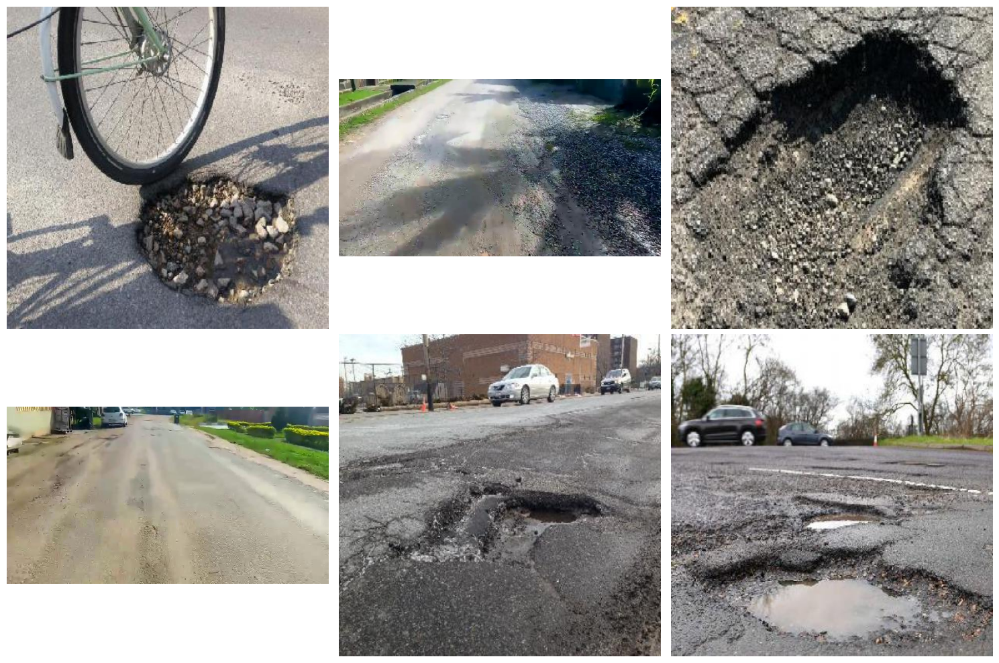

In [ ]:
import cv2
import matplotlib.pyplot as plt
import glob

images = glob.glob("/content/train/images/*")

plt.figure(figsize=(15, 10))

for i, image_path in enumerate(images[:6]):

    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

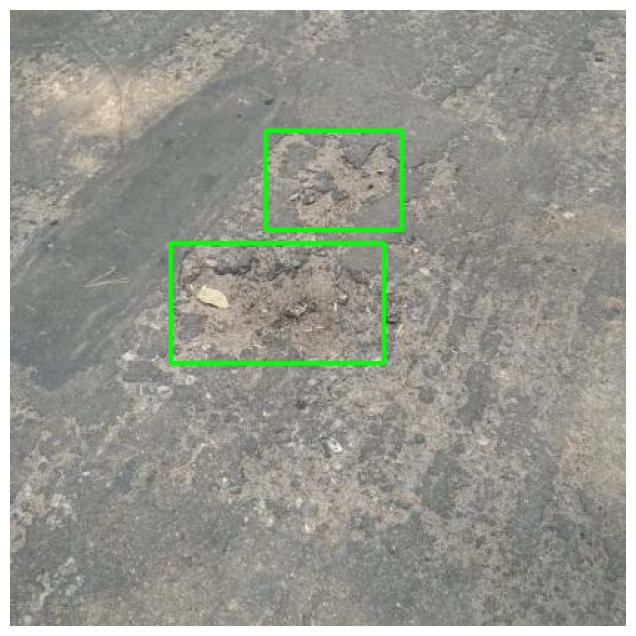

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os
import random

image_dir = "/content/train/images"
label_dir = "/content/train/labels"

images = os.listdir(image_dir)

image_name = random.choice(images)

image_path = os.path.join(image_dir, image_name)

label_name = os.path.splitext(image_name)[0] + ".txt"
label_path = os.path.join(label_dir, label_name)

img = cv2.imread(image_path)

h, w, _ = img.shape

with open(label_path) as f:

    for line in f:

        values = line.strip().split()

        class_id, x, y, bw, bh = map(float, values)

        x1 = int((x - bw/2) * w)
        y1 = int((y - bh/2) * h)

        x2 = int((x + bw/2) * w)
        y2 = int((y + bh/2) * h)

        cv2.rectangle(
            img,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
import os

for split in ["train", "valid", "test"]:

    image_dir = f"/content/{split}/images"
    label_dir = f"/content/{split}/labels"

    images = os.listdir(image_dir)

    missing = []

    for image in images:

        label = os.path.splitext(image)[0] + ".txt"

        if not os.path.exists(os.path.join(label_dir, label)):
            missing.append(image)

    print(f"{split}: Missing labels = {len(missing)}")

train: Missing labels = 0
valid: Missing labels = 0
test: Missing labels = 0


In [ ]:
import os

invalid_boxes = []

for split in ["train", "valid", "test"]:

    label_dir = f"/content/{split}/labels"

    for file in os.listdir(label_dir):

        if not file.endswith(".txt"):
            continue

        path = os.path.join(label_dir, file)

        with open(path) as f:

            for line_num, line in enumerate(f, start=1):

                values = line.strip().split()

                try:
                    if len(values) != 5:
                        raise ValueError("Expected 5 values")

                    cls, x, y, w, h = map(float, values)

                    if (
                        cls < 0 or
                        not cls.is_integer() or
                        not (0 <= x <= 1) or
                        not (0 <= y <= 1) or
                        not (0 < w <= 1) or
                        not (0 < h <= 1) or
                        x - w/2 < 0 or
                        y - h/2 < 0 or
                        x + w/2 > 1 or
                        y + h/2 > 1
                    ):
                        raise ValueError("Invalid bounding box")

                except ValueError as e:

                    invalid_boxes.append(
                        (split, file, line_num, str(e))
                    )

print("Invalid annotations:", len(invalid_boxes))
print(invalid_boxes[:10])

Invalid annotations: 66
[('train', '703_png.rf.6c4b548fe89a94d1435f391d60fc83b8.txt', 2, 'Invalid bounding box'), ('train', '120_png.rf.4b274aa4ba0cf682f0ccb380b191033f.txt', 1, 'Invalid bounding box'), ('train', '779_png.rf.c0eaebf4222fcabf3ee8819aee85184e.txt', 7, 'Invalid bounding box'), ('train', '157_png.rf.c1b658834360c011243bd1164c97a965.txt', 2, 'Invalid bounding box'), ('train', '296_png.rf.e29f903e3fd4ae3ad3028441c449ebf2.txt', 2, 'Invalid bounding box'), ('train', '132_png.rf.eacc3e5d86b92c147a9882a0ebc83022.txt', 3, 'Invalid bounding box'), ('train', '852_png.rf.28115ce89273da4e7c20ffcb51689b82.txt', 5, 'Invalid bounding box'), ('train', '026_png.rf.40ba75fd5cf3388af5a4deeec42a702d.txt', 3, 'Invalid bounding box'), ('train', '108_png.rf.d494eb5981dfe3c41bd7050ce81facb6.txt', 7, 'Invalid bounding box'), ('train', '108_png.rf.d494eb5981dfe3c41bd7050ce81facb6.txt', 8, 'Invalid bounding box')]


In [ ]:
import os
import yaml
from collections import Counter

with open("/content/data.yaml") as f:
    config = yaml.safe_load(f)

num_classes = config["nc"]

issues = Counter()
invalid_details = []

for split in ["train", "valid", "test"]:

    label_dir = f"/content/{split}/labels"

    for file in os.listdir(label_dir):

        if not file.endswith(".txt"):
            continue

        path = os.path.join(label_dir, file)

        with open(path) as f:

            for line_num, line in enumerate(f, 1):

                values = line.strip().split()

                try:
                    if len(values) != 5:
                        raise ValueError("Incorrect number of values")

                    cls, x, y, w, h = map(float, values)

                    reasons = []

                    if not cls.is_integer() or not (0 <= cls < num_classes):
                        reasons.append("Invalid class ID")

                    if not all(map(lambda v: v == v and abs(v) != float("inf"),
                                   [cls, x, y, w, h])):
                        reasons.append("Non-finite value")

                    if not (0 <= x <= 1 and 0 <= y <= 1):
                        reasons.append("Center outside image")

                    if not (0 < w <= 1 and 0 < h <= 1):
                        reasons.append("Invalid width/height")

                    if x - w/2 < 0 or x + w/2 > 1:
                        reasons.append("Horizontal boundary violation")

                    if y - h/2 < 0 or y + h/2 > 1:
                        reasons.append("Vertical boundary violation")

                    for reason in set(reasons):
                        issues[reason] += 1

                    if reasons:
                        invalid_details.append(
                            (split, file, line_num, values, reasons)
                        )

                except ValueError as e:
                    invalid_details.append(
                        (split, file, line_num, values, [str(e)])
                    )

print("ISSUE SUMMARY:")
print(issues)

print("\nFIRST 15 INVALID ANNOTATIONS:")

for item in invalid_details[:15]:
    print(item)

ISSUE SUMMARY:
Counter({'Horizontal boundary violation': 39, 'Vertical boundary violation': 28})

FIRST 15 INVALID ANNOTATIONS:
('train', '703_png.rf.6c4b548fe89a94d1435f391d60fc83b8.txt', 2, ['0', '0.1879375', '0.8879545454545454', '0.1536875', '0.22411931818181818'], ['Vertical boundary violation'])
('train', '120_png.rf.4b274aa4ba0cf682f0ccb380b191033f.txt', 1, ['0', '0.10571875', '0.5351704545454545', '0.21145312500000002', '0.194375'], ['Horizontal boundary violation'])
('train', '779_png.rf.c0eaebf4222fcabf3ee8819aee85184e.txt', 7, ['0', '0.45629687499999994', '0.8759943181818183', '0.28153125', '0.24803977272727273'], ['Vertical boundary violation'])
('train', '157_png.rf.c1b658834360c011243bd1164c97a965.txt', 2, ['0', '0.8971718750000001', '0.4437784090909091', '0.205671875', '0.22900568181818182'], ['Horizontal boundary violation'])
('train', '296_png.rf.e29f903e3fd4ae3ad3028441c449ebf2.txt', 2, ['0', '0.031453125', '0.7559659090909091', '0.062921875', '0.09636363636363637'], 

In [ ]:
import shutil
import os

backup_path = "/content/labels_backup"

if not os.path.exists(backup_path):
    shutil.copytree(
        "/content/train/labels",
        backup_path
    )

print("Backup created successfully!")

Backup created successfully!


In [ ]:
import os

splits = ["train", "valid", "test"]

corrected = 0
removed = 0

for split in splits:

    label_dir = f"/content/{split}/labels"

    for file in os.listdir(label_dir):

        if not file.endswith(".txt"):
            continue

        path = os.path.join(label_dir, file)

        new_lines = []

        with open(path, "r") as f:
            lines = f.readlines()

        for line in lines:

            values = line.strip().split()

            if len(values) != 5:
                removed += 1
                continue

            cls, x, y, w, h = map(float, values)

            # Convert center coordinates to corners
            x1 = x - w / 2
            y1 = y - h / 2
            x2 = x + w / 2
            y2 = y + h / 2

            # Clip coordinates
            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(1, x2)
            y2 = min(1, y2)

            # Check valid box
            if x2 <= x1 or y2 <= y1:
                removed += 1
                continue

            # Convert back to YOLO format
            new_x = (x1 + x2) / 2
            new_y = (y1 + y2) / 2

            new_w = x2 - x1
            new_h = y2 - y1

            new_lines.append(
                f"{int(cls)} {new_x:.8f} {new_y:.8f} "
                f"{new_w:.8f} {new_h:.8f}\n"
            )

            if (x1 != x - w/2 or
                y1 != y - h/2 or
                x2 != x + w/2 or
                y2 != y + h/2):

                corrected += 1

        with open(path, "w") as f:
            f.writelines(new_lines)

print("Corrected annotations:", corrected)
print("Removed annotations:", removed)

Corrected annotations: 66
Removed annotations: 0


In [ ]:
model = YOLO("yolo11n.pt")

WARNING ⚠️ Download failure, retrying 1/3 in 5s https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt... 504 Server Error: Gateway Time-out for url: https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt
WARNING ⚠️ Download failure, retrying 2/3 in 10s https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt... 504 Server Error: Gateway Time-out for url: https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt
WARNING ⚠️ Download failure, retrying 3/3 in 20s https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt... 504 Server Error: Gateway Time-out for url: https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo11n.pt


In [ ]:
results = model.train(
    data="/content/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=20,
    optimizer="auto",
    project="Road_Damage_Detection",
    name="YOLO11n_Baseline",
    save=True,
    plots=True
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n_Baseline, nbs=64, nms=None, opset=None, optimize=False, opti

In [ ]:
from ultralytics import YOLO

best_model = YOLO(
    '/content/runs/detect/Road_Damage_Detection/YOLO11n_Baseline/weights/best.pt'
)

In [ ]:
metrics = best_model.val(
    data="/content/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 775.0±249.5 MB/s, size: 43.4 KB)
val: Scanning /content/test/labels... 174 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 853.7it/s 0.2s
val: New cache created: /content/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 4.1it/s 2.7s
                   all        174        605      0.874      0.825      0.888      0.554
Speed: 1.3ms preprocess, 4.4ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val


In [ ]:
best_model.predict(
    source="/content/test/images",
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True,
    imgsz=640
)


image 1/174 /content/test/images/021_png.rf.c904af104e710041c48957494dd1d975.jpg: 352x640 5 potholes, 29.6ms
image 2/174 /content/test/images/032_png.rf.0bd49c680d52579fc327372abf1206b0.jpg: 352x640 5 potholes, 53.7ms
image 3/174 /content/test/images/036_png.rf.c57dc2a96f1ab2b1ca0d126726008a2e.jpg: 352x640 5 potholes, 59.1ms
image 4/174 /content/test/images/043_png.rf.0945940ab8e40ea4ee2a42460857b16d.jpg: 352x640 6 potholes, 42.6ms
image 5/174 /content/test/images/047_png.rf.1f853372bb06d3fdbaadac449621c38f.jpg: 352x640 7 potholes, 37.2ms
image 6/174 /content/test/images/054_png.rf.bd71db6fdb47f2f07f4350b6492e8b03.jpg: 352x640 9 potholes, 45.9ms
image 7/174 /content/test/images/083_png.rf.9a9e22ef197cec3988d4fdeac704d4e1.jpg: 352x640 12 potholes, 62.9ms
image 8/174 /content/test/images/091_png.rf.07e5c6894a9121d6b587418778679b36.jpg: 352x640 12 potholes, 44.3ms
image 9/174 /content/test/images/098_png.rf.601dd16b845a93e38e4b584d346c5e89.jpg: 352x640 13 potholes, 34.0ms
image 10/174 /c

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'pothole'}
 obb: None
 orig_img: array([[[104, 104, 104],
         [ 65,  65,  65],
         [103, 103, 103],
         ...,
         [ 80,  73,  56],
         [ 80,  73,  56],
         [ 80,  73,  56]],
 
        [[107, 107, 107],
         [ 68,  68,  68],
         [ 91,  91,  91],
         ...,
         [ 80,  73,  56],
         [ 80,  73,  56],
         [ 80,  73,  56]],
 
        [[103, 103, 103],
         [ 74,  74,  74],
         [ 89,  89,  89],
         ...,
         [ 80,  73,  56],
         [ 80,  73,  56],
         [ 80,  73,  56]],
 
        ...,
 
        [[100, 125, 145],
         [100, 125, 145],
         [100, 125, 145],
         ...,
         [255, 255, 255],
         [255, 255, 255],
         [255, 255, 255]],
 
        [[100, 125, 145],
         [100, 125, 145],
         [100, 125, 145],
    

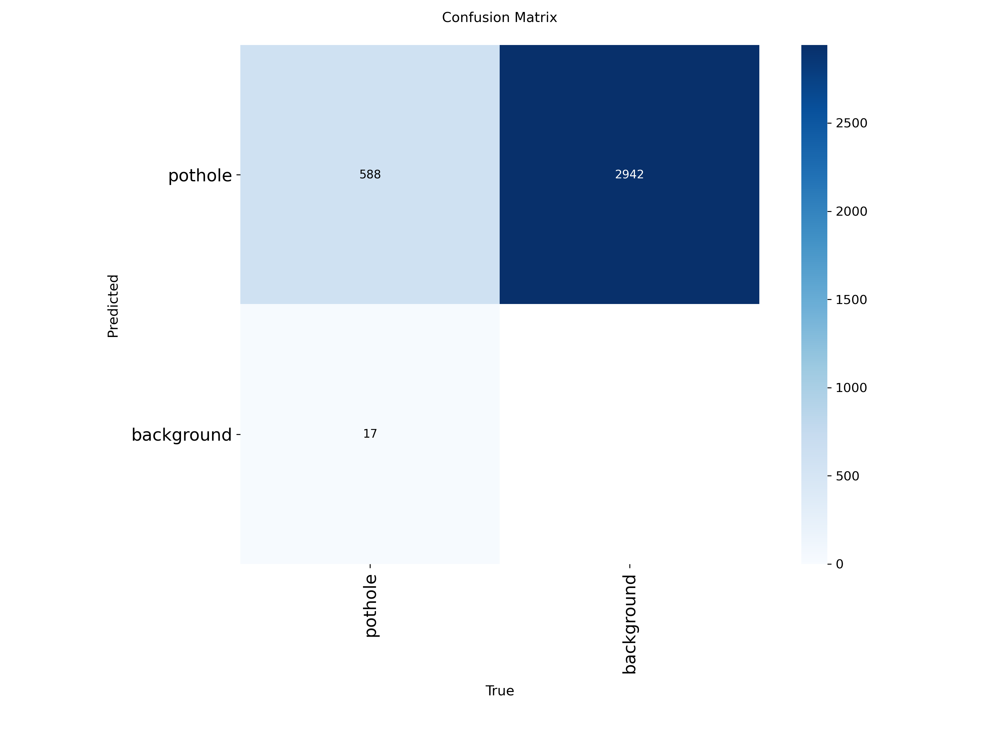

In [ ]:
from IPython.display import Image, display

display(
    Image("/content/runs/detect/val/confusion_matrix.png")
)

In [ ]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/runs/detect/Road_Damage_Detection/YOLO11n_Baseline/weights/best.pt"
)

thresholds = [0.10, 0.25, 0.40, 0.50, 0.60]

for conf in thresholds:

    metrics = best_model.val(
        data="/content/data.yaml",
        split="test",
        imgsz=640,
        conf=conf,
        device=0,
        plots=False,
        verbose=False
    )

    print(f"\nConfidence: {conf}")
    print("Precision:", metrics.box.mp)
    print("Recall:", metrics.box.mr)
    print("mAP50:", metrics.box.map50)


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1142.8±274.3 MB/s, size: 35.3 KB)
val: Scanning /content/test/labels.cache... 174 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 45.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 5.7it/s 1.9s
                   all        174        605      0.874      0.825      0.854      0.536
Speed: 1.0ms preprocess, 3.9ms inference, 0.0ms loss, 1.8ms postprocess per image

Confidence: 0.1
Precision: 0.8740501752078393
Recall: 0.824793388429752
mAP50: 0.8542499368705632
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1621.9±671.

In [ ]:
results = best_model.predict(
    source="/content/test/images",
    conf=0.25,
    imgsz=640,
    save=True,
    save_txt=True,
    save_conf=True
)


image 1/174 /content/test/images/021_png.rf.c904af104e710041c48957494dd1d975.jpg: 352x640 5 potholes, 30.6ms
image 2/174 /content/test/images/032_png.rf.0bd49c680d52579fc327372abf1206b0.jpg: 352x640 5 potholes, 32.2ms
image 3/174 /content/test/images/036_png.rf.c57dc2a96f1ab2b1ca0d126726008a2e.jpg: 352x640 5 potholes, 18.4ms
image 4/174 /content/test/images/043_png.rf.0945940ab8e40ea4ee2a42460857b16d.jpg: 352x640 6 potholes, 16.6ms
image 5/174 /content/test/images/047_png.rf.1f853372bb06d3fdbaadac449621c38f.jpg: 352x640 7 potholes, 18.9ms
image 6/174 /content/test/images/054_png.rf.bd71db6fdb47f2f07f4350b6492e8b03.jpg: 352x640 9 potholes, 15.6ms
image 7/174 /content/test/images/083_png.rf.9a9e22ef197cec3988d4fdeac704d4e1.jpg: 352x640 12 potholes, 15.9ms
image 8/174 /content/test/images/091_png.rf.07e5c6894a9121d6b587418778679b36.jpg: 352x640 12 potholes, 19.5ms
image 9/174 /content/test/images/098_png.rf.601dd16b845a93e38e4b584d346c5e89.jpg: 352x640 13 potholes, 18.9ms
image 10/174 /c

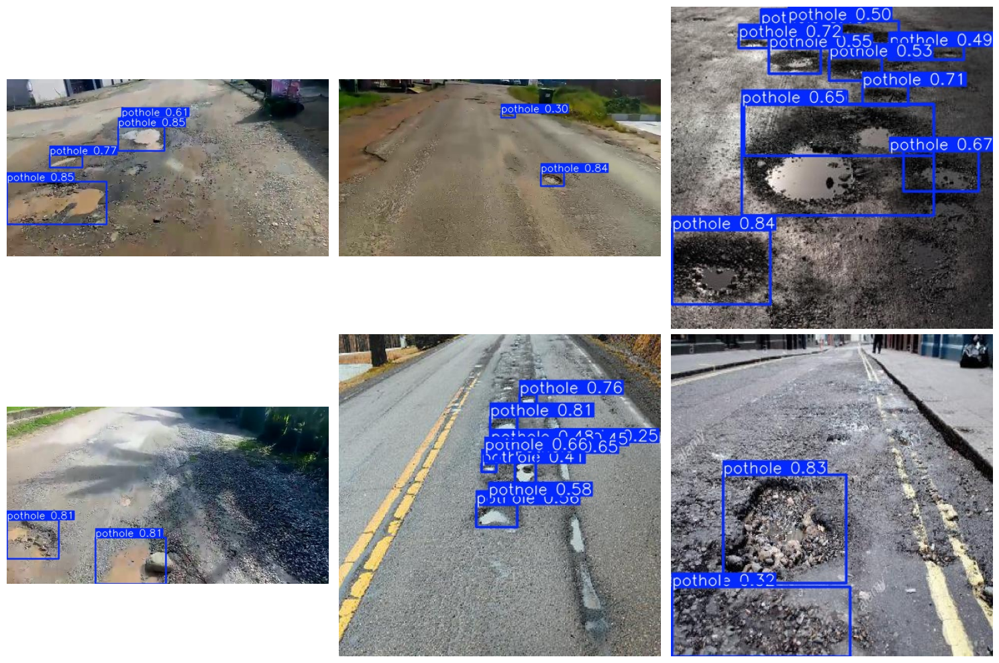

In [ ]:
import glob
import matplotlib.pyplot as plt
import cv2

images = glob.glob(
    "/content/runs/detect/predict/*.jpg"
)

plt.figure(figsize=(15, 10))

for i, path in enumerate(images[:6]):

    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i+1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
results = best_model.predict(
    source="/content/test/images",
    conf=0.25,
    iou=0.45,
    imgsz=640,
    save=True,
    project="/content/Road_Analysis",
    name="NMS_Experiment",
    exist_ok=True
)


image 1/174 /content/test/images/021_png.rf.c904af104e710041c48957494dd1d975.jpg: 352x640 5 potholes, 10.6ms
image 2/174 /content/test/images/032_png.rf.0bd49c680d52579fc327372abf1206b0.jpg: 352x640 5 potholes, 9.2ms
image 3/174 /content/test/images/036_png.rf.c57dc2a96f1ab2b1ca0d126726008a2e.jpg: 352x640 5 potholes, 9.4ms
image 4/174 /content/test/images/043_png.rf.0945940ab8e40ea4ee2a42460857b16d.jpg: 352x640 6 potholes, 9.9ms
image 5/174 /content/test/images/047_png.rf.1f853372bb06d3fdbaadac449621c38f.jpg: 352x640 7 potholes, 12.8ms
image 6/174 /content/test/images/054_png.rf.bd71db6fdb47f2f07f4350b6492e8b03.jpg: 352x640 9 potholes, 12.6ms
image 7/174 /content/test/images/083_png.rf.9a9e22ef197cec3988d4fdeac704d4e1.jpg: 352x640 12 potholes, 10.8ms
image 8/174 /content/test/images/091_png.rf.07e5c6894a9121d6b587418778679b36.jpg: 352x640 12 potholes, 18.9ms
image 9/174 /content/test/images/098_png.rf.601dd16b845a93e38e4b584d346c5e89.jpg: 352x640 13 potholes, 15.9ms
image 10/174 /cont

In [ ]:
best_model.val(
    data="/content/data.yaml",
    split="test",
    imgsz=640,
    plots=True,
    save_json=True
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 851.0±149.9 MB/s, size: 32.1 KB)
val: Scanning /content/test/labels.cache... 174 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 45.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.5it/s 4.5s
                   all        174        605      0.874      0.825      0.888      0.554
Speed: 3.0ms preprocess, 5.4ms inference, 0.0ms loss, 3.2ms postprocess per image
Saving /content/runs/detect/val-7/predictions.json...

Evaluating faster-coco-eval mAP...
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 158ms
Prepared 1 package in 26ms
Installed 1 package in 2ms
 + faster-c

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ecf64777700>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

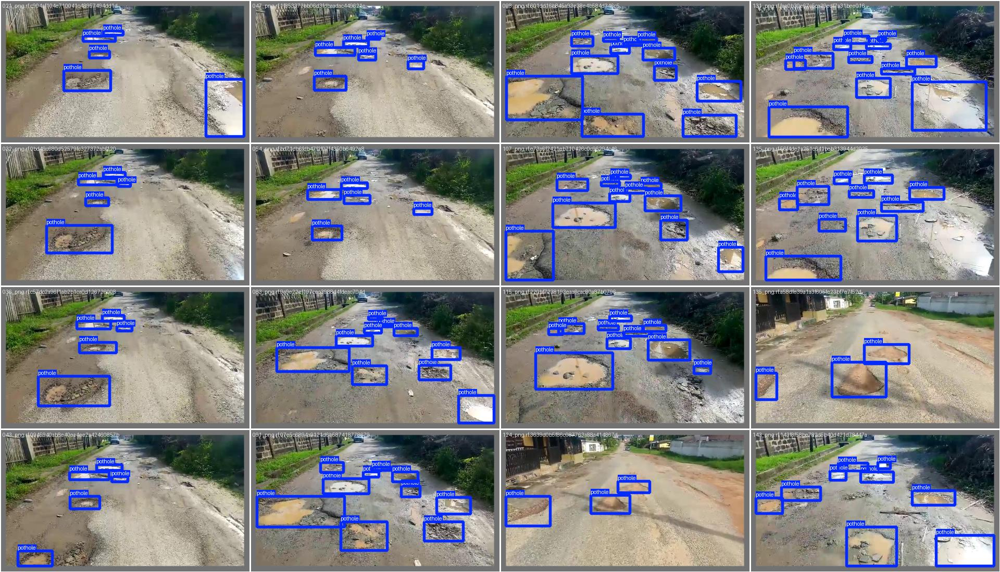

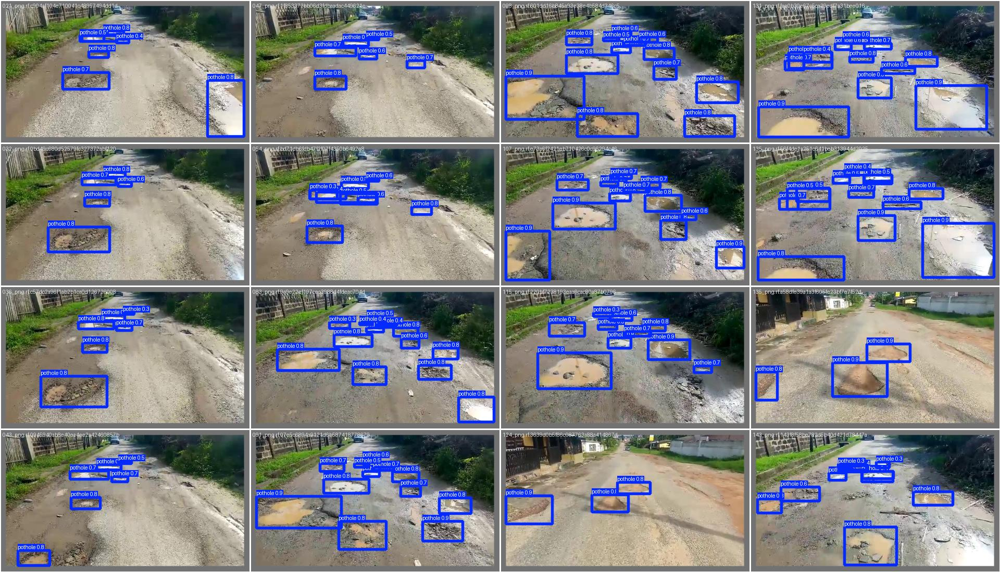

In [ ]:
from IPython.display import Image, display

display(Image("/content/runs/detect/val/val_batch0_labels.jpg"))

display(Image("/content/runs/detect/val/val_batch0_pred.jpg"))

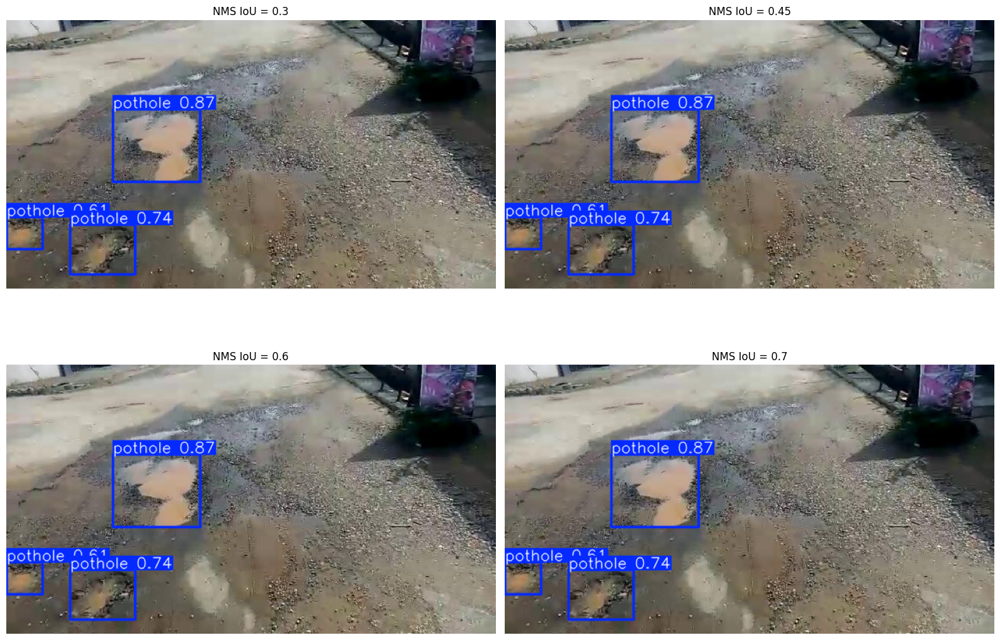

In [ ]:
import glob
import os
import matplotlib.pyplot as plt
import cv2

image_path = glob.glob("/content/valid/images/*")[0]

thresholds = [0.30, 0.45, 0.60, 0.70]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, threshold in zip(axes.flatten(), thresholds):

    results = best_model.predict(
        source=image_path,
        conf=0.25,
        iou=threshold,
        imgsz=640,
        verbose=False
    )

    plotted_image = results[0].plot()

    plotted_image = cv2.cvtColor(
        plotted_image,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(plotted_image)
    ax.set_title(f"NMS IoU = {threshold}")
    ax.axis("off")

plt.tight_layout()
plt.show()

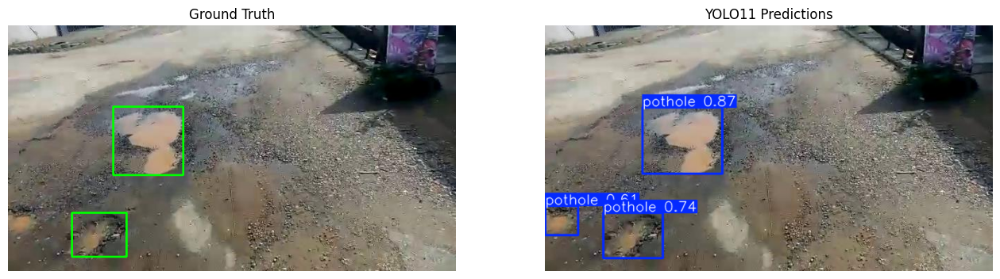

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

# Select an image
image_path = "/content/valid/images/" + os.listdir(
    "/content/valid/images"
)[0]

# Corresponding annotation
image_name = os.path.splitext(
    os.path.basename(image_path)
)[0]

label_path = f"/content/valid/labels/{image_name}.txt"

# Load image
img = cv2.imread(image_path)
h, w = img.shape[:2]

# Ground truth visualization
gt_img = img.copy()

with open(label_path) as f:

    for line in f:

        cls, x, y, bw, bh = map(
            float, line.strip().split()
        )

        x1 = int((x - bw/2) * w)
        y1 = int((y - bh/2) * h)
        x2 = int((x + bw/2) * w)
        y2 = int((y + bh/2) * h)

        cv2.rectangle(
            gt_img,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

# Model prediction
results = best_model.predict(
    source=image_path,
    conf=0.25,
    iou=0.45,
    verbose=False
)

pred_img = results[0].plot()

# Display comparison
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(gt_img, cv2.COLOR_BGR2RGB))
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB))
plt.title("YOLO11 Predictions")
plt.axis("off")

plt.show()

In [ ]:
import torch

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [ ]:
import os

image_name = os.path.splitext(
    os.path.basename(image_path)
)[0]

label_path = f"/content/valid/labels/{image_name}.txt"

# Ground truth boxes
gt_boxes = []

with open(label_path) as f:

    for line in f:

        cls, x, y, w, h = map(float, line.split())

        gt_boxes.append([
            (x-w/2)*640,
            (y-h/2)*640,
            (x+w/2)*640,
            (y+h/2)*640
        ])

# Predicted boxes
results = best_model.predict(
    image_path,
    conf=0.25,
    verbose=False
)

pred_boxes = results[0].boxes.xyxy.cpu().numpy()

# Compare
for i, pred in enumerate(pred_boxes):

    print(f"\nPrediction {i+1}")

    for j, gt in enumerate(gt_boxes):

        iou = calculate_iou(pred, gt)

        print(f"Ground Truth {j+1}: IoU = {iou:.4f}")


Prediction 1
Ground Truth 1: IoU = 0.0049
Ground Truth 2: IoU = 0.0000

Prediction 2
Ground Truth 1: IoU = 0.0525
Ground Truth 2: IoU = 0.0000

Prediction 3
Ground Truth 1: IoU = 0.0000
Ground Truth 2: IoU = 0.0000


In [ ]:
import cv2
import os
import numpy as np

# Read original image dimensions
img = cv2.imread(image_path)

H, W = img.shape[:2]

print("Original Width:", W)
print("Original Height:", H)

# Load ground truth boxes
gt_boxes = []

with open(label_path) as f:

    for line in f:

        cls, x, y, w, h = map(float, line.split())

        gt_boxes.append([
            (x - w/2) * W,
            (y - h/2) * H,
            (x + w/2) * W,
            (y + h/2) * H
        ])

# Get predictions
results = best_model.predict(
    image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)

pred_boxes = results[0].boxes.xyxy.cpu().numpy()

# IoU function
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# Compare predictions with ground truth
for i, pred in enumerate(pred_boxes):

    print(f"\nPrediction {i+1}")

    for j, gt in enumerate(gt_boxes):

        iou = calculate_iou(pred, gt)

        print(f"Ground Truth {j+1}: IoU = {iou:.4f}")

Original Width: 640
Original Height: 352

Prediction 1
Ground Truth 1: IoU = 0.8561
Ground Truth 2: IoU = 0.0000

Prediction 2
Ground Truth 1: IoU = 0.0000
Ground Truth 2: IoU = 0.8519

Prediction 3
Ground Truth 1: IoU = 0.0000
Ground Truth 2: IoU = 0.0000


In [ ]:
from ultralytics import YOLO
import numpy as np
from pathlib import Path

model = best_model

image_dir = Path("/content/valid/images")
label_dir = Path("/content/valid/labels")

ious = []

tp = 0
fp = 0
fn = 0

for image_path in image_dir.iterdir():

    if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    label_path = label_dir / (image_path.stem + ".txt")

    img_results = model.predict(
        str(image_path),
        conf=0.25,
        iou=0.7,
        verbose=False
    )[0]

    pred_boxes = img_results.boxes.xyxy.cpu().numpy()

    gt_boxes = []

    if label_path.exists():

        img = img_results.orig_img
        h, w = img.shape[:2]

        with open(label_path) as f:

            for line in f:

                cls, x, y, bw, bh = map(float, line.split())

                gt_boxes.append([
                    (x-bw/2)*w,
                    (y-bh/2)*h,
                    (x+bw/2)*w,
                    (y+bh/2)*h
                ])

    matched_gt = set()

    for pred in pred_boxes:

        best_iou = 0
        best_gt = -1

        for j, gt in enumerate(gt_boxes):

            if j in matched_gt:
                continue

            iou_value = calculate_iou(pred, gt)

            if iou_value > best_iou:

                best_iou = iou_value
                best_gt = j

        if best_iou >= 0.50:

            tp += 1
            matched_gt.add(best_gt)
            ious.append(best_iou)

        else:
            fp += 1

    fn += len(gt_boxes) - len(matched_gt)

print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)

print("Mean matched IoU:",
      np.mean(ious) if ious else 0)

print("Precision:", tp/(tp+fp) if tp+fp else 0)
print("Recall:", tp/(tp+fn) if tp+fn else 0)


True Positives: 850
False Positives: 244
False Negatives: 120
Mean matched IoU: 0.81806165
Precision: 0.7769652650822669
Recall: 0.8762886597938144


In [ ]:
thresholds = [0.10, 0.20, 0.25, 0.30, 0.40, 0.50]

for threshold in thresholds:

    tp = 0
    fp = 0
    fn = 0

    for image_path in image_dir.iterdir():

        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png"
        ]:
            continue

        label_path = label_dir / (
            image_path.stem + ".txt"
        )

        result = best_model.predict(
            str(image_path),
            conf=threshold,
            iou=0.45,
            verbose=False
        )[0]

        pred_boxes = result.boxes.xyxy.cpu().numpy()

        gt_boxes = []

        if label_path.exists():

            h, w = result.orig_img.shape[:2]

            with open(label_path) as f:

                for line in f:

                    cls, x, y, bw, bh = map(
                        float, line.split()
                    )

                    gt_boxes.append([
                        (x-bw/2)*w,
                        (y-bh/2)*h,
                        (x+bw/2)*w,
                        (y+bh/2)*h
                    ])

        matched = set()

        for pred in pred_boxes:

            candidates = [
                (calculate_iou(pred, gt), j)
                for j, gt in enumerate(gt_boxes)
                if j not in matched
            ]

            if candidates:

                best_iou, best_gt = max(candidates)

                if best_iou >= 0.50:

                    tp += 1
                    matched.add(best_gt)

                else:
                    fp += 1

            else:
                fp += 1

        fn += len(gt_boxes) - len(matched)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"Confidence: {threshold} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Confidence: 0.1 | Precision: 0.6959 | Recall: 0.9155 | F1: 0.7907
Confidence: 0.2 | Precision: 0.7814 | Recall: 0.8845 | F1: 0.8298
Confidence: 0.25 | Precision: 0.8117 | Recall: 0.8711 | F1: 0.8404
Confidence: 0.3 | Precision: 0.8285 | Recall: 0.8567 | F1: 0.8424
Confidence: 0.4 | Precision: 0.8712 | Recall: 0.8299 | F1: 0.8501
Confidence: 0.5 | Precision: 0.9102 | Recall: 0.7938 | F1: 0.8480


In [ ]:
from ultralytics import YOLO

model_800 = YOLO(
    "/content/runs/detect/Road_Damage_Detection/YOLO11n_Baseline/weights/best.pt"
)

results_800 = model_800.train(
    data="/content/data.yaml",
    epochs=100,
    imgsz=800,
    batch=8,
    device=0,
    workers=2,
    patience=20,
    optimizer="auto",
    project="Road_Damage_Detection",
    name="YOLO11n_800",
    save=True,
    plots=True
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/Road_Damage_Detection/YOLO11n_Baseline/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/runs/detect/Road_Damage_Detection/YOLO11n_800/weights/best.pt"
)

In [ ]:
results = model.predict(
    source="/content/0x0.png",
    conf=0.4,
    imgsz=800,
    save=True
)


image 1/1 /content/0x0.png: 544x800 15 potholes, 8.5ms
Speed: 2.4ms preprocess, 8.5ms inference, 1.4ms postprocess per image at shape (1, 3, 544, 800)
Results saved to /content/runs/detect/predict-3


In [ ]:
results = model.predict(
    source="/content/0x0.png",
    conf=0.60,
    iou=0.45,
    imgsz=800,
    save=True,
    project="/content/Road_Analysis",
    name="high_confidence"
)


image 1/1 /content/0x0.png: 544x800 13 potholes, 10.5ms
Speed: 2.4ms preprocess, 10.5ms inference, 1.9ms postprocess per image at shape (1, 3, 544, 800)
Results saved to /content/Road_Analysis/high_confidence


In [ ]:
results = model.predict(
    source="/content/0x0.png",
    conf=0.60,
    iou=0.45,
    imgsz=800,
    verbose=False
)

result = results[0]

print("Total detections:", len(result.boxes))

print("Confidence scores:")

print(result.boxes.conf.cpu().numpy())

Total detections: 13
Confidence scores:
[    0.88593     0.84961     0.83537     0.80502     0.79119     0.74046      0.7178     0.70888     0.68634      0.6753     0.64126     0.62244     0.60937]


In [ ]:
from google.colab import files

files.download(
    "/content/runs/detect/Road_Damage_Detection/YOLO11n_800/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>